# Mobile Game Player Spending Segmentation
## Dataset generation

NovaPlay Studios uses in-app purchases as a key revenue stream and aims to increase IAP revenue by **15% within three months of deploying the predictive ML model(Q1 2027)** through more relevant player offers. This project prepares data to study whether a player's demographic profile and early gameplay can help classify them within the first **30-day period** as a **Minnow** (low or no spending), **Dolphin** (moderate spending), or **Whale** (high spending).

This notebook starts with the 3,024-row, 13-column Kaggle source, preserves those original records, generates 244,476 simulated player records, adds 10 simulated features, and appends 2,500 duplicate records for the cleaning exercise. The resulting dataset has **250,000 rows and 23 columns**. Generated records are synthetic; they are not additional Kaggle observations.

**Output:** `mobile_game_players_expanded_dirty.csv`.

## 1. Download Kaggle data

In [1]:
# KaggleHub is Kaggle's supported Python library. Public datasets may download without login;
# if consent/authentication is required, the next step falls back to your uploaded ZIP or CSV.
!pip -q install kagglehub
from pathlib import Path
import kagglehub

DATASET_HANDLE = 'pratyushpuri/mobile-game-in-app-purchases-dataset-2025'
try:
    downloaded_dir = Path(kagglehub.dataset_download(DATASET_HANDLE))
    matches = list(downloaded_dir.rglob('mobile_game_inapp_purchases.csv'))
    if not matches:
        matches = list(downloaded_dir.rglob('*.csv'))
    if not matches:
        raise FileNotFoundError('No CSV file was found in Kaggle download.')
    SOURCE_CSV = matches[0]
    print('Downloaded from Kaggle:', SOURCE_CSV)
except Exception as e:
    print('Automatic Kaggle download did not work:', repr(e))
    print('Upload the Kaggle archive.zip or mobile_game_inapp_purchases.csv instead.')
    from google.colab import files
    import zipfile
    uploaded = files.upload()
    uploaded_path = Path(next(iter(uploaded)))
    if uploaded_path.suffix.lower() == '.zip':
        with zipfile.ZipFile(uploaded_path) as z:
            z.extractall('kaggle_source')
        matches = list(Path('kaggle_source').rglob('mobile_game_inapp_purchases.csv'))
        if not matches:
            raise FileNotFoundError('Expected Kaggle CSV was not found in uploaded ZIP.')
        SOURCE_CSV = matches[0]
    else:
        SOURCE_CSV = uploaded_path
print('Using base CSV:', SOURCE_CSV)


100%|██████████| 522k/522k [00:00<00:00, 1.29MB/s]

Extracting files...
Downloaded from Kaggle: /root/.cache/kagglehub/datasets/pratyushpuri/mobile-game-in-app-purchases-dataset-2025/versions/1/mobile_game_inapp_purchases.csv
Using base CSV: /root/.cache/kagglehub/datasets/pratyushpuri/mobile-game-in-app-purchases-dataset-2025/versions/1/mobile_game_inapp_purchases.csv


## 2. Imports, settings, and source check

In [ ]:
import numpy as np
import pandas as pd
SEED = 20261109
FINAL_ROWS = 250_000
OUTPUT_FILENAME = 'mobile_game_players_expanded_dirty.csv'
source = pd.read_csv(SOURCE_CSV)
print('Original Kaggle file:', source.shape)
print('Original columns:', source.columns.tolist())
display(source.head())
assert len(source) == 3024, 'Confirm the source file is the expected Kaggle CSV before proceeding.'


Original Kaggle file: (3024, 13)
Original columns: ['UserID', 'Age', 'Gender', 'Country', 'Device', 'GameGenre', 'SessionCount', 'AverageSessionLength', 'SpendingSegment', 'InAppPurchaseAmount', 'FirstPurchaseDaysAfterInstall', 'PaymentMethod', 'LastPurchaseDate']


,UserID,Age,Gender,Country,Device,GameGenre,SessionCount,AverageSessionLength,SpendingSegment,InAppPurchaseAmount,FirstPurchaseDaysAfterInstall,PaymentMethod,LastPurchaseDate
0,c9889ab0-9cfc-4a75-acd9-5eab1df0015c,49.0,Male,Norway,Android,Battle Royale,9,12.83,Minnow,11.40,28.0,Apple Pay,2025-03-19
1,7c9e413c-ecca-45f2-a780-2826a07952a2,15.0,Male,Switzerland,iOS,Action RPG,11,19.39,Minnow,6.37,18.0,Debit Card,2025-06-08
2,fd61e419-1a92-4f43-a8c7-135842ad328a,23.0,Male,China,Android,Fighting,9,8.87,Minnow,15.81,30.0,Apple Pay,2025-06-02
3,bdb7f6d1-ff9a-468c-afe7-43f32a94293e,31.0,Male,Mexico,Android,Racing,12,19.56,Minnow,13.49,9.0,Debit Card,2025-04-01
4,aa7eec14-4846-47b9-b879-9c98038cda04,37.0,Female,India,Android,Battle Royale,10,15.23,Minnow,10.86,15.0,Paypal,2025-05-05


## Before generation: inspect the Kaggle source

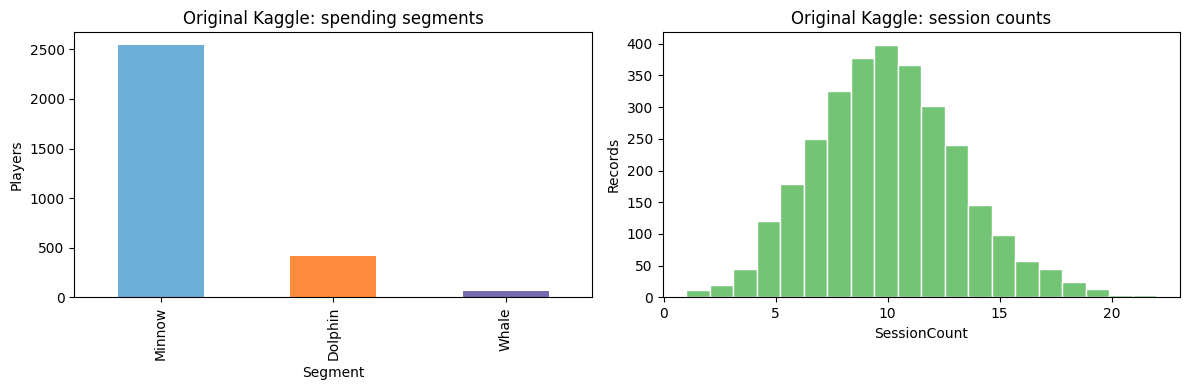

Original null counts:


,missing_rows
UserID,0
Age,60
Gender,60
Country,60
Device,60
GameGenre,60
SessionCount,0
AverageSessionLength,0
SpendingSegment,0
InAppPurchaseAmount,136


In [ ]:
# Quick source-only views: class mix and original numeric distributions.
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
source['SpendingSegment'].value_counts().reindex(['Minnow','Dolphin','Whale']).plot.bar(ax=axes[0], color=['#6baed6','#fd8d3c','#756bb1'])
axes[0].set_title('Original Kaggle: spending segments')
axes[0].set_xlabel('Segment'); axes[0].set_ylabel('Players')
session = pd.to_numeric(source['SessionCount'], errors='coerce').dropna()
axes[1].hist(session, bins=20, color='#74c476', edgecolor='white')
axes[1].set_title('Original Kaggle: session counts')
axes[1].set_xlabel('SessionCount'); axes[1].set_ylabel('Records')
plt.tight_layout(); plt.show()
print('Original null counts:')
display(source.isna().sum().to_frame('missing_rows'))


## 3. Generate and expand the dataset
This cell preserves original records, resamples from their distribution to create additional players, adds 10 related features, injects realistic quality problems into generated records, and appends duplicates. Output has exactly 250,000 rows and 23 columns.

In [ ]:
# The generator function is embedded below so the notebook runs independently.
import numpy as np
import pandas as pd
from pathlib import Path
TOTAL_ROWS = FINAL_ROWS

def expand(source_path, output_path, total_rows=TOTAL_ROWS, seed=SEED):
    src=pd.read_csv(source_path)
    expected={'UserID','Age','Gender','Country','Device','GameGenre','SessionCount','AverageSessionLength','SpendingSegment','InAppPurchaseAmount','FirstPurchaseDaysAfterInstall','PaymentMethod','LastPurchaseDate'}
    missing=expected-set(src.columns)
    if missing: raise ValueError(f"Source CSV is missing expected Kaggle columns: {sorted(missing)}")
    if total_rows < 200_000 or total_rows <= len(src): raise ValueError('Output must be at least 200,000 rows and larger than source.')
    rng=np.random.default_rng(seed)
    n_orig=len(src); n_duplicates=round(total_rows*.01); n_synthetic=total_rows-n_orig-n_duplicates
    # Sample from the original distribution with replacement, retaining its target-class mix.
    synth=src.iloc[rng.integers(0,n_orig,size=n_synthetic)].reset_index(drop=True).copy()
    synth['UserID']=[f'SYN{i:07d}' for i in range(1,n_synthetic+1)]
    # Perturb continuous variables mildly to create plausible, non-identical simulated players.
    ages=pd.to_numeric(synth['Age'],errors='coerce')
    synth['Age']=np.where(ages.notna(),np.clip(np.rint(ages+rng.normal(0,3,n_synthetic)),13,75),np.nan)
    sessions=pd.to_numeric(synth['SessionCount'],errors='coerce').fillna(8).to_numpy()
    synth['SessionCount']=np.maximum(1,np.rint(sessions*rng.lognormal(0,.25,n_synthetic))).astype(int)
    duration=pd.to_numeric(synth['AverageSessionLength'],errors='coerce').fillna(15).to_numpy()
    synth['AverageSessionLength']=(duration*rng.lognormal(0,.18,n_synthetic)).round(2)
    amounts=pd.to_numeric(synth['InAppPurchaseAmount'],errors='coerce').fillna(0).to_numpy(copy=True)
    # Preserve target coherence: amount remains within the selected source segment's band.
    seg=synth['SpendingSegment'].astype(str).str.strip().str.lower()
    is_whale=seg.eq('whale').to_numpy(); is_dolphin=seg.eq('dolphin').to_numpy(); is_minnow=~(is_whale|is_dolphin)
    amounts[is_whale]=np.clip(amounts[is_whale]*rng.lognormal(0,.16,is_whale.sum()),500,5000)
    amounts[is_dolphin]=np.clip(amounts[is_dolphin]*rng.lognormal(0,.18,is_dolphin.sum()),20.01,499.99)
    amounts[is_minnow]=np.clip(amounts[is_minnow]*rng.lognormal(0,.20,is_minnow.sum()),0,19.99)
    synth['InAppPurchaseAmount']=np.round(amounts,2)
    days=pd.to_numeric(synth['FirstPurchaseDaysAfterInstall'],errors='coerce').to_numpy()
    days=np.where(np.isnan(days),days,np.clip(np.rint(days+rng.normal(0,3,n_synthetic)),0,90))
    synth['FirstPurchaseDaysAfterInstall']=days
    # Add 10 relevant features, making 23 columns total.
    synth['AcquisitionChannel']=rng.choice(['Organic','Paid Social','Search Ads','Influencer','Referral','Cross-promotion'],n_synthetic,p=[.25,.24,.14,.12,.13,.12])
    last=pd.to_datetime(synth['LastPurchaseDate'],errors='coerce')
    install=last-pd.to_timedelta(rng.integers(0,901,n_synthetic),unit='D')
    synth['InstallDate']=install
    sess=pd.to_numeric(synth['SessionCount'],errors='coerce').fillna(8).to_numpy()
    synth['ActiveDays30d']=np.clip(rng.poisson(np.clip(sess*.65,1,28)),1,30)
    synth['PlayerLevel30d']=np.maximum(1,np.rint(sess*rng.uniform(.5,2.0,n_synthetic))).astype(int)
    synth['AdsWatched30d']=rng.poisson(5+(synth['GameGenre'].astype(str).str.contains('Puzzle').to_numpy()*3))
    synth['SocialActions30d']=rng.poisson(4+(synth['GameGenre'].astype(str).str.contains('MOBA').to_numpy()*3))
    # Extra fields depend on observed game activity/genre, not directly on the target label.
    guild_prob=np.clip(.18 + sess/45 + (synth['GameGenre'].astype(str).str.contains('MOBA').to_numpy()*.08),.18,.78)
    synth['GuildMember']=np.where(rng.random(n_synthetic)<guild_prob,'Yes','No')
    push_prob=np.clip(.38 + sess/60,.38,.80)
    synth['PushNotificationsOptIn']=np.where(rng.random(n_synthetic)<push_prob,'Yes','No')
    synth['PurchaseCount30d']=rng.poisson(np.clip(sess/7,0,7)).astype(int)
    genre_bonus=np.select([synth['GameGenre'].astype(str).str.contains('MOBA'),synth['GameGenre'].astype(str).str.contains('Battle Royale')],[.06,.04],default=0)
    synth['WinRate']=np.clip(rng.beta(4,6,n_synthetic)+genre_bonus+rng.normal(0,.04,n_synthetic),0,1).round(3)
    # Preserve source order and structure while adding fields with missing values for original rows.
    extra=['AcquisitionChannel','InstallDate','ActiveDays30d','PlayerLevel30d','AdsWatched30d','SocialActions30d','GuildMember','PushNotificationsOptIn','PurchaseCount30d','WinRate']
    for col in extra: src[col]=np.nan
    full=pd.concat([src,synth],ignore_index=True)
    # Deliberate quality problems injected into synthetic rows (not fabricated claims about Kaggle).
    syn_idx=np.arange(n_orig,len(full))
    def miss(col,rate):
        ix=rng.choice(syn_idx,size=int(rate*len(syn_idx)),replace=False); full.loc[ix,col]=np.nan
    for c,r in {'Age':.025,'Gender':.018,'Country':.035,'AverageSessionLength':.04,'AcquisitionChannel':.05,'FirstPurchaseDaysAfterInstall':.12,'PaymentMethod':.045,'LastPurchaseDate':.03,'InAppPurchaseAmount':.025,'SessionCount':.02}.items(): miss(c,r)
    def aliases(col,frac,mapping):
        ix=rng.choice(syn_idx,size=int(frac*len(syn_idx)),replace=False)
        full.loc[ix,col]=full.loc[ix,col].map(lambda v:mapping.get(v,v) if pd.notna(v) else v)
    aliases('Device',.035,{'Android':'android','iOS':'IOS'})
    aliases('Country',.025,{'UAE':'United Arab Emirates','USA':'usa','UK':'United Kingdom'})
    aliases('GameGenre',.025,{'Battle Royale':'BattleRoyale','Action RPG':'action rpg'})
    aliases('SpendingSegment',.02,{'Whale':'whale','Dolphin':'DOLPHIN','Minnow':'Minnow '})
    aliases('PaymentMethod',.025,{'PayPal':'Paypal','Credit Card':'CreditCard','Google Pay':'GooglePay'})
    # Mixed date formats and textual-unit/type errors.
    for col,frac,fmt in [('InstallDate',.18,'%m/%d/%Y'),('LastPurchaseDate',.12,'%d-%m-%Y')]:
        ix=rng.choice(syn_idx,size=int(frac*len(syn_idx)),replace=False)
        parsed=pd.to_datetime(full.loc[ix,col],errors='coerce')
        full.loc[ix,col]=parsed.dt.strftime(fmt).to_numpy()
    ix=rng.choice(syn_idx,size=int(.012*len(syn_idx)),replace=False)
    full['AverageSessionLength']=full['AverageSessionLength'].astype(object)
    vals=pd.to_numeric(full.loc[ix,'AverageSessionLength'],errors='coerce')
    full.loc[ix,'AverageSessionLength']=(vals*60).round().astype('Int64').astype(str)+' sec'
    ix=rng.choice(syn_idx,size=int(.01*len(syn_idx)),replace=False)
    full['InAppPurchaseAmount']=full['InAppPurchaseAmount'].astype(object)
    vals=pd.to_numeric(full.loc[ix,'InAppPurchaseAmount'],errors='coerce').fillna(0)
    full.loc[ix,'InAppPurchaseAmount']='$'+vals.round(2).astype(str)
    # Impossible values and outliers in generated rows.
    k=int(.003*len(syn_idx)); ix=rng.choice(syn_idx,size=k,replace=False); full.loc[ix,'Age']=-rng.integers(1,10,k)
    k=int(.002*len(syn_idx)); ix=rng.choice(syn_idx,size=k,replace=False); full.loc[ix,'SessionCount']=-rng.integers(1,30,k)
    k=int(.001*len(syn_idx)); ix=rng.choice(syn_idx,size=k,replace=False); full.loc[ix,'AverageSessionLength']=rng.uniform(240,900,k)
    k=int(.001*len(syn_idx)); ix=rng.choice(syn_idx,size=k,replace=False); full.loc[ix,'WinRate']=rng.uniform(1.2,2.0,k)
    full.loc[n_orig,'InstallDate']='2035-01-01'
    # Append copied records to create exact duplicates; output has exactly total_rows.
    dup=full.sample(n=n_duplicates,random_state=seed+77)
    result=pd.concat([full,dup],ignore_index=True)
    out=Path(output_path); out.parent.mkdir(parents=True,exist_ok=True); result.to_csv(out,index=False)
    print(f'Original Kaggle rows preserved: {n_orig:,}')
    print(f'Synthetic rows generated: {n_synthetic:,}')
    print(f'Duplicate rows appended: {n_duplicates:,}')
    print(f'Final shape: {result.shape[0]:,} rows x {result.shape[1]} columns')
    print(f'Saved to: {out.resolve()}')
    return result



expanded = expand(SOURCE_CSV, OUTPUT_FILENAME, total_rows=FINAL_ROWS, seed=SEED)


/tmp/ipykernel_531/4002782357.py:58: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full=pd.concat([src,synth],ignore_index=True)


Original Kaggle rows preserved: 3,024
Synthetic rows generated: 244,476
Duplicate rows appended: 2,500
Final shape: 250,000 rows x 23 columns
Saved to: /content/mobile_game_players_expanded_dirty.csv


## After generation: compare before and after

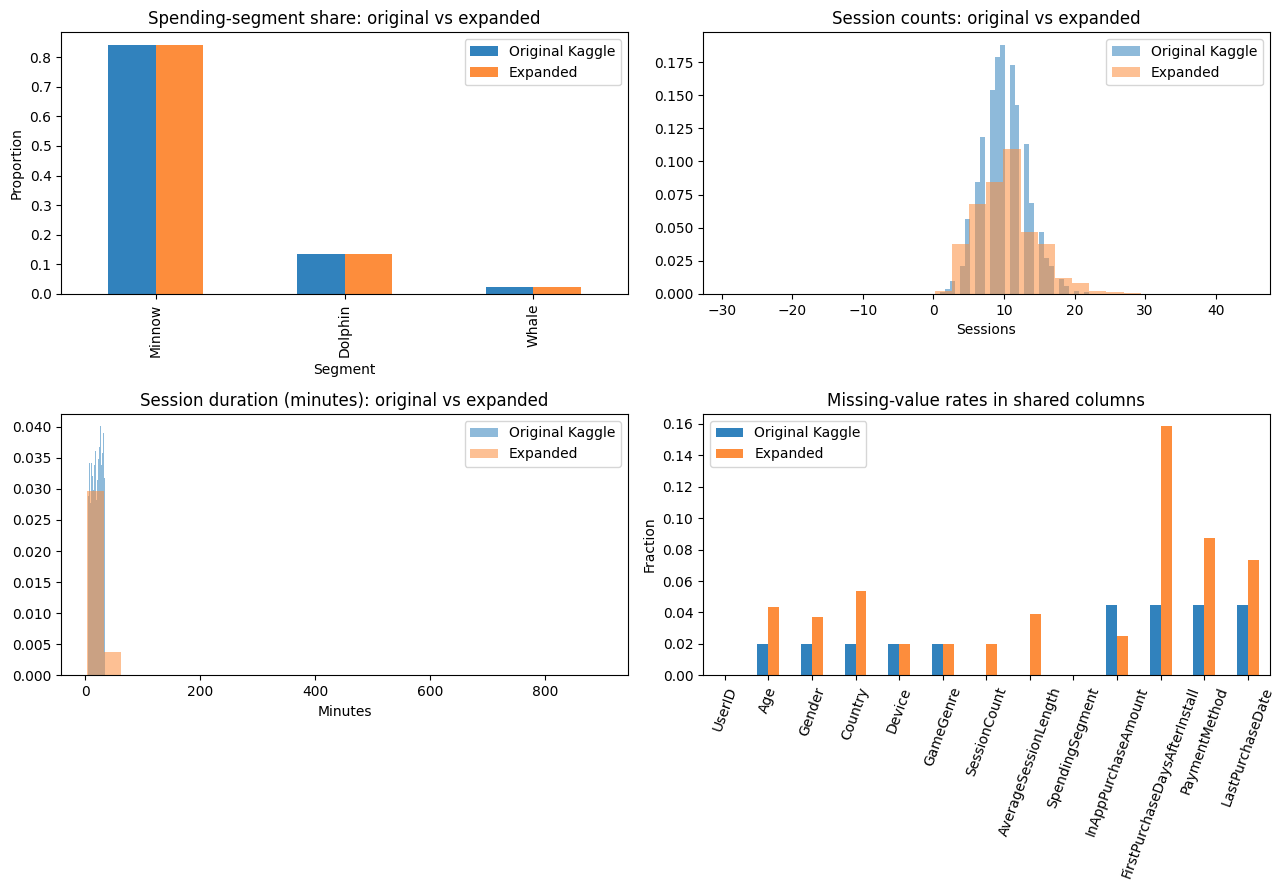

Final size: (250000, 23) | exact duplicate rows: 2500
Interpretation: differences are expected because generated records were resampled/perturbed and deliberate quality problems were injected. These are synthetic patterns, not new measured facts about gamers.


In [ ]:
# Canonicalize labels only for plotting so intentional case/space variants are grouped.
def canonical_segment(s):
    return s.astype('string').str.strip().str.lower().map({'minnow':'Minnow','dolphin':'Dolphin','whale':'Whale'})
base_share = canonical_segment(source['SpendingSegment']).value_counts(normalize=True).reindex(['Minnow','Dolphin','Whale'])
expanded_share = canonical_segment(expanded['SpendingSegment']).value_counts(normalize=True).reindex(['Minnow','Dolphin','Whale'])

# Parse duration variants for visualization only; the source dataset itself remains unchanged.
def duration_minutes(series):
    s=series.astype('string').str.strip()
    sec=s.str.extract(r'^([0-9.]+)\s*sec$', expand=False)
    numeric=pd.to_numeric(s,errors='coerce')
    numeric.loc[sec.notna()] = pd.to_numeric(sec[sec.notna()],errors='coerce')/60
    return numeric

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
plot_df=pd.DataFrame({'Original Kaggle':base_share,'Expanded':expanded_share})
plot_df.plot.bar(ax=axes[0,0], color=['#3182bd','#fd8d3c'])
axes[0,0].set_title('Spending-segment share: original vs expanded')
axes[0,0].set_ylabel('Proportion'); axes[0,0].set_xlabel('Segment')
for name, series, color in [('Original Kaggle',source['SessionCount'],'#3182bd'),('Expanded',expanded['SessionCount'],'#fd8d3c')]:
    vals=pd.to_numeric(series,errors='coerce').dropna()
    axes[0,1].hist(vals,bins=30,density=True,alpha=.55,label=name,color=color)
axes[0,1].set_title('Session counts: original vs expanded'); axes[0,1].set_xlabel('Sessions'); axes[0,1].legend()
for name, series, color in [('Original Kaggle',source['AverageSessionLength'],'#3182bd'),('Expanded',expanded['AverageSessionLength'],'#fd8d3c')]:
    vals=duration_minutes(series).dropna()
    axes[1,0].hist(vals,bins=30,density=True,alpha=.55,label=name,color=color)
axes[1,0].set_title('Session duration (minutes): original vs expanded'); axes[1,0].set_xlabel('Minutes'); axes[1,0].legend()
common=[c for c in source.columns if c in expanded.columns]
missing_compare=pd.DataFrame({'Original Kaggle':source[common].isna().mean(),'Expanded':expanded[common].isna().mean()})
missing_compare.plot.bar(ax=axes[1,1],color=['#3182bd','#fd8d3c'])
axes[1,1].set_title('Missing-value rates in shared columns'); axes[1,1].set_ylabel('Fraction'); axes[1,1].tick_params(axis='x',rotation=70)
plt.tight_layout(); plt.show()
print('Final size:', expanded.shape, '| exact duplicate rows:', int(expanded.duplicated().sum()))
print('Interpretation: differences are expected because generated records were resampled/perturbed and deliberate quality problems were injected. These are synthetic patterns, not new measured facts about gamers.')


## 4. Inspect and download

In [ ]:
print('Final dimensions:', expanded.shape)
print('Exact duplicates:', int(expanded.duplicated().sum()))
print('Missing values (%):')
display((expanded.isna().mean()*100).round(2).to_frame('missing_percent'))
print('Target labels (some variants are deliberately inconsistent):')
display(expanded['SpendingSegment'].value_counts(dropna=False).to_frame('records'))


Final dimensions: (250000, 23)
Exact duplicates: 2500
Missing values (%):


,missing_percent
UserID,0.00
Age,4.37
Gender,3.73
Country,5.37
Device,2.00
GameGenre,1.99
SessionCount,1.98
AverageSessionLength,3.91
SpendingSegment,0.00
InAppPurchaseAmount,2.50


Target labels (some variants are deliberately inconsistent):


,records
SpendingSegment,
Minnow,206250
Dolphin,33357
Whale,5450
Minnow,4161
DOLPHIN,660
whale,122


In [ ]:
from google.colab import files
files.download(OUTPUT_FILENAME)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## What is original and what is generated?
- Original source: Kaggle CSV, 3,024 records and 13 columns.
- Final dataset: 250,000 records and 23 columns.
- The original rows are retained; newly simulated rows are generated by resampling source rows and perturbing values; 1% duplicates are deliberately appended. The output filename is `mobile_game_players_expanded_dirty.csv`.
- Ten added features: `AcquisitionChannel`, `InstallDate`, `ActiveDays30d`, `PlayerLevel30d`, `AdsWatched30d`, `SocialActions30d`, `GuildMember`, `PushNotificationsOptIn`, `PurchaseCount30d`, `WinRate`.
- Deliberate issues: missingness, category aliases/case variations, mixed date formats, session durations in seconds-as-text, currency text, duplicate records, negative age/session counts, outliers, future install date.


